     Year                                    Public_Feedback  Sentiment_Score
0    2006  The new solar plant in Shivamogga is amazing a...         0.312121
1    2007  I am disappointed with the slow progress of re...        -0.525000
2    2008  Good initiative by the government, but mainten...         0.700000
3    2009  Renewable energy is the future! Great to see t...         0.400000
4    2010  Very satisfied with the off-grid solar install...         0.650000
..    ...                                                ...              ...
630  2020  The new solar plant in Shivamogga is amazing a...         0.312121
631  2021  I am disappointed with the slow progress of re...        -0.525000
632  2022  Good initiative by the government, but mainten...         0.700000
633  2023  Renewable energy is the future! Great to see t...         0.400000
634  2024  Very satisfied with the off-grid solar install...         0.650000

[635 rows x 3 columns]


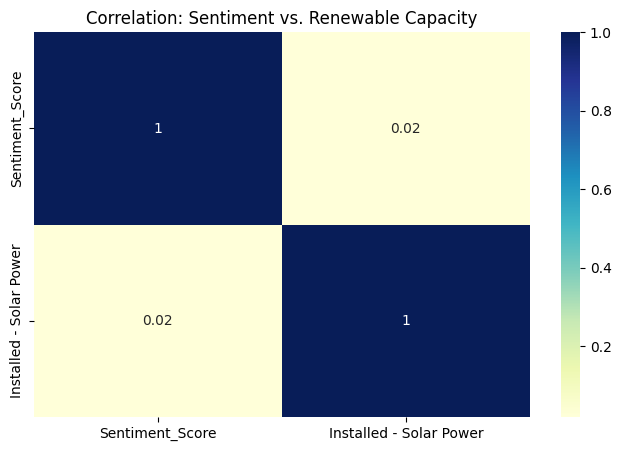

In [ ]:
import pandas as pd
from textblob import TextBlob
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('/content/drive/MyDrive/NLP_Project/renewable_energy_dataset.csv')

# 2. Synthetic Text Generation (Since the original file lacks text)
# We add a 'Public_Feedback' column to demonstrate NLP techniques
feedback_list = [
    "The new solar plant in Shivamogga is amazing and very efficient.",
    "I am disappointed with the slow progress of renewable projects this year.",
    "Good initiative by the government, but maintenance is lacking.",
    "Renewable energy is the future! Great to see the capacity increasing.",
    "Very satisfied with the off-grid solar installation. It saves a lot of money."
]
# Repeat the feedback list to match the DataFrame's length
df['Public_Feedback'] = [feedback_list[i % len(feedback_list)] for i in range(len(df))]

# 3. Sentiment Analysis (Polarity recognition)
df['Sentiment_Score'] = df['Public_Feedback'].apply(lambda x: TextBlob(x).sentiment.polarity)

# 4. TF-IDF Vectorization
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['Public_Feedback'])
tfidf_features = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())

# 5. Word Vectors (Reference Code)
# Note: Word2Vec requires the 'gensim' library.
!pip install gensim
from gensim.models import Word2Vec
sentences = [text.split() for text in df['Public_Feedback']]
w2v_model = Word2Vec(sentences, vector_size=10, window=5, min_count=1, workers=4)
word_vector = w2v_model.wv['solar']

# 6. Correlation Relation
# Comparing Sentiment Score with Cumulative Installed Capacity
target_col = 'Installed - Solar Power'
correlation = df[['Sentiment_Score', target_col]].corr()

# 7. Visualization
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='YlGnBu')
plt.title('Correlation: Sentiment vs. Renewable Capacity')
plt.savefig('sentiment_correlation.png')

# Save results
df.to_csv('analyzed_renewable_sentiment.csv', index=False)
print(df[['Year', 'Public_Feedback', 'Sentiment_Score']])

Pearson Correlation Matrix:


,Year,Installed - Bio-Mass Power,Installed - Small Hydro Power,Installed - Solar Power,Installed - Wind Power,Installed - Waste to Energy,Population,GSDP (crore INR),Sentiment_Score
Year,1.000000,0.224517,0.118103,0.349622,0.180347,0.350233,0.042573,0.334615,-0.006573
Installed - Bio-Mass Power,0.224517,1.000000,0.436173,0.409374,0.481290,0.425558,0.625348,0.782497,0.007167
Installed - Small Hydro Power,0.118103,0.436173,1.000000,0.287514,0.272086,0.042310,0.118651,0.335899,0.006273
Installed - Solar Power,0.349622,0.409374,0.287514,1.000000,0.633601,0.380673,0.251102,0.557136,0.019765
Installed - Wind Power,0.180347,0.481290,0.272086,0.633601,1.000000,0.244748,0.346826,0.720948,0.019007
Installed - Waste to Energy,0.350233,0.425558,0.042310,0.380673,0.244748,1.000000,0.288386,0.473527,-0.020323
Population,0.042573,0.625348,0.118651,0.251102,0.346826,0.288386,1.000000,0.679408,0.006452
GSDP (crore INR),0.334615,0.782497,0.335899,0.557136,0.720948,0.473527,0.679408,1.000000,0.017717
Sentiment_Score,-0.006573,0.007167,0.006273,0.019765,0.019007,-0.020323,0.006452,0.017717,1.000000


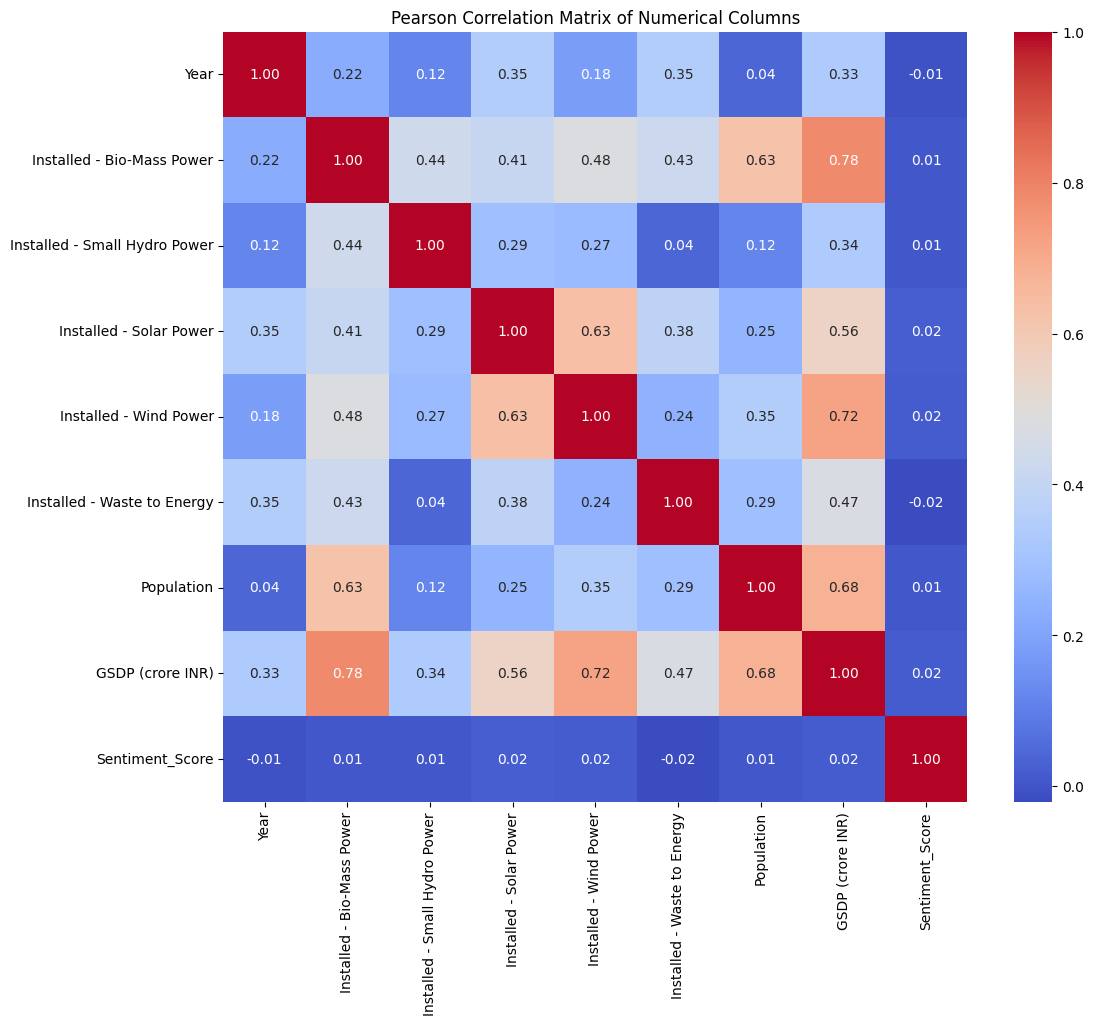

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the Pearson correlation matrix for all numerical columns
pearson_correlation = df.select_dtypes(include=['number']).corr(method='pearson')

print('Pearson Correlation Matrix:')
display(pearson_correlation)

# Visualize the Pearson correlation matrix using a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(pearson_correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Pearson Correlation Matrix of Numerical Columns')
plt.show()

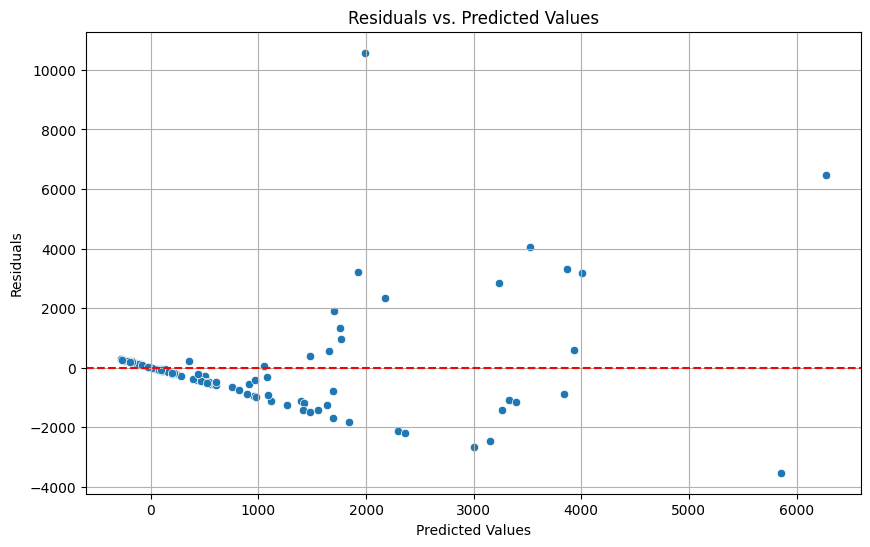

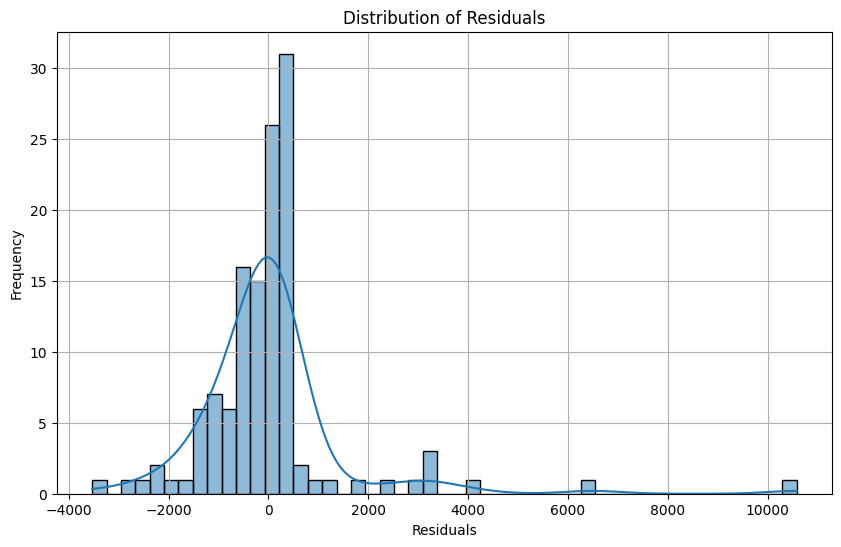

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
residuals = y_test - y_pred

# Plotting residuals against predicted values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals vs. Predicted Values')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

# Plotting histogram of residuals
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True)
plt.title('Distribution of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

These plots help to assess the assumptions of linear regression. Ideally, residuals should be randomly scattered around zero (no discernible pattern in the scatter plot) and follow a normal distribution (bell-shaped histogram).

R-squared: 0.4884
Mean Squared Error (MSE): 2320681.4943
Coefficient (GSDP): 0.0032
Intercept: -277.5405


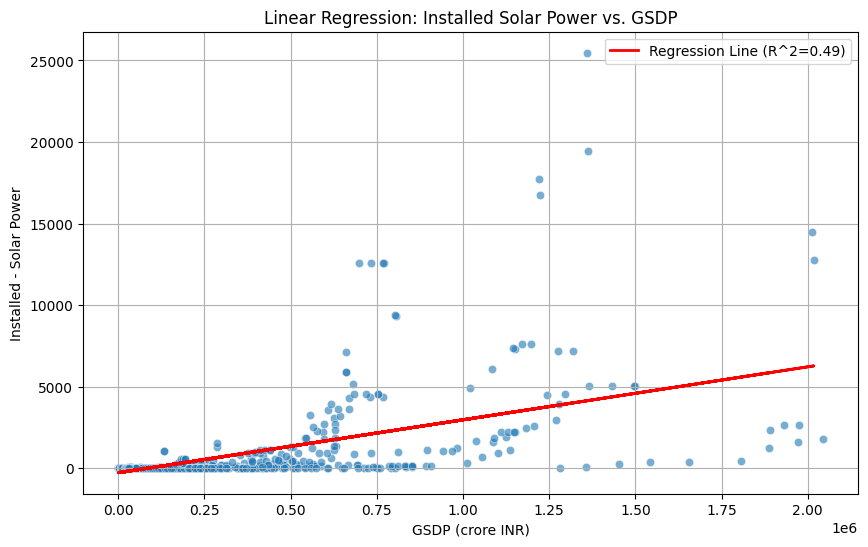

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the independent (X) and dependent (y) variables
# Reshape X to be a 2D array as required by scikit-learn
X = df[['GSDP (crore INR)']].values
y = df['Installed - Solar Power'].values

# Split the data into training and testing sets (optional, but good practice)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a linear regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
r_squared = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
coefficient = model.coef_[0]
intercept = model.intercept_

print(f"R-squared: {r_squared:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Coefficient (GSDP): {coefficient:.4f}")
print(f"Intercept: {intercept:.4f}")

# Visualize the regression
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['GSDP (crore INR)'], y=df['Installed - Solar Power'], alpha=0.6)
plt.plot(X_test, y_pred, color='red', linewidth=2, label=f'Regression Line (R^2={r_squared:.2f})')
plt.title('Linear Regression: Installed Solar Power vs. GSDP')
plt.xlabel('GSDP (crore INR)')
plt.ylabel('Installed - Solar Power')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

# Define conditions for sentiment categories
conditions = [
    df['Sentiment_Score'] > 0,
    df['Sentiment_Score'] < 0,
    df['Sentiment_Score'] == 0
]

# Define choices for sentiment categories
choices = ['Positive', 'Negative', 'Neutral']

# Create a new column 'Sentiment_Category' based on the conditions
df['Sentiment_Category'] = np.select(conditions, choices, default='Neutral')

# Display the count of each sentiment category
display(df['Sentiment_Category'].value_counts())

,count
Sentiment_Category,
Positive,508
Negative,127


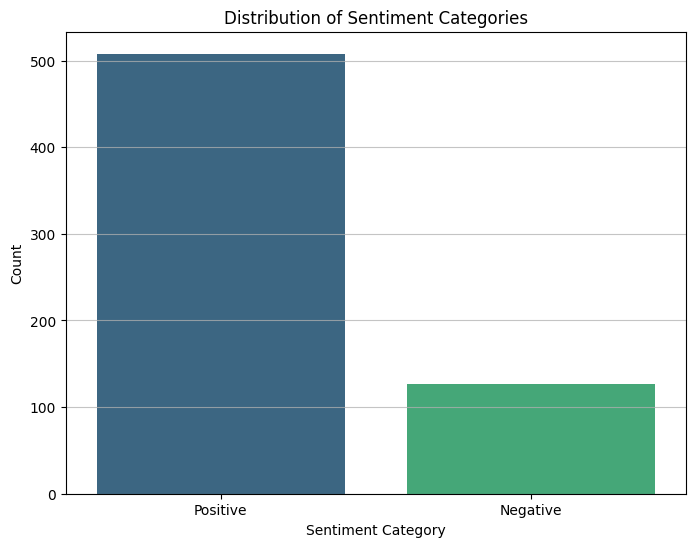

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the value counts of the 'Sentiment_Category' column
sentiment_counts = df['Sentiment_Category'].value_counts()

# Create a bar plot
plt.figure(figsize=(8, 6))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, hue=sentiment_counts.index, palette='viridis', legend=False)
plt.title('Distribution of Sentiment Categories')
plt.xlabel('Sentiment Category')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
!pip install wordcloud

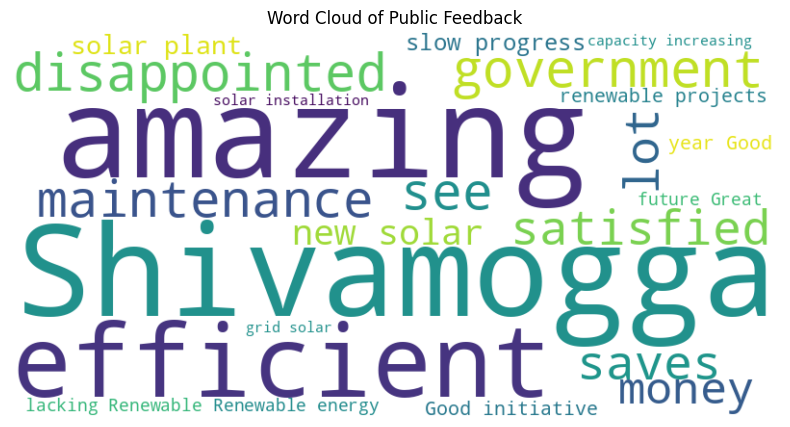

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all feedback into a single string
all_feedback_text = ' '.join(df['Public_Feedback'])

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_feedback_text)

# Display the generated image:
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Public Feedback')
plt.show()

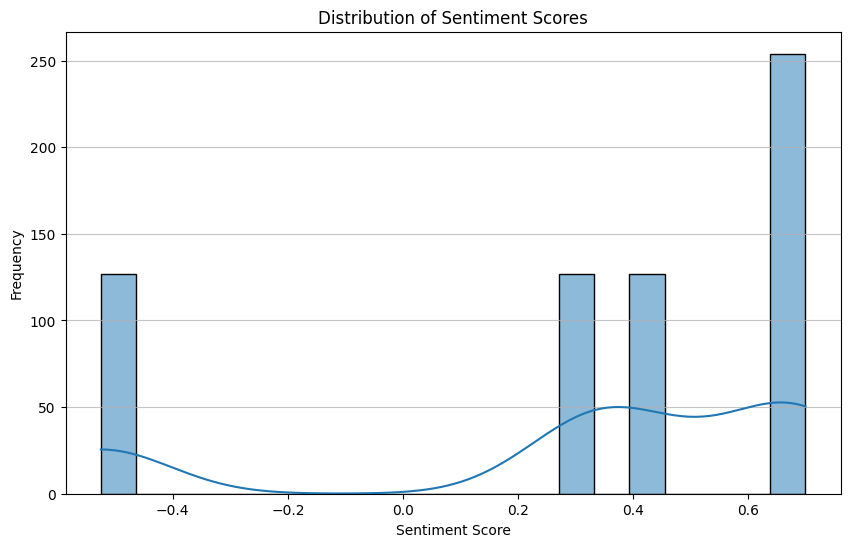

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Sentiment_Score'], bins=20, kde=True)
plt.title('Distribution of Sentiment Scores')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
# Filter feedback that specifically mentions 'solar'
solar_feedback_df = df[df['Public_Feedback'].str.contains('solar', case=False, na=False)]

# Get the value counts of sentiment categories for solar-related feedback
solar_sentiment_counts = solar_feedback_df['Sentiment_Category'].value_counts()

display(solar_sentiment_counts)

,count
Sentiment_Category,
Positive,254


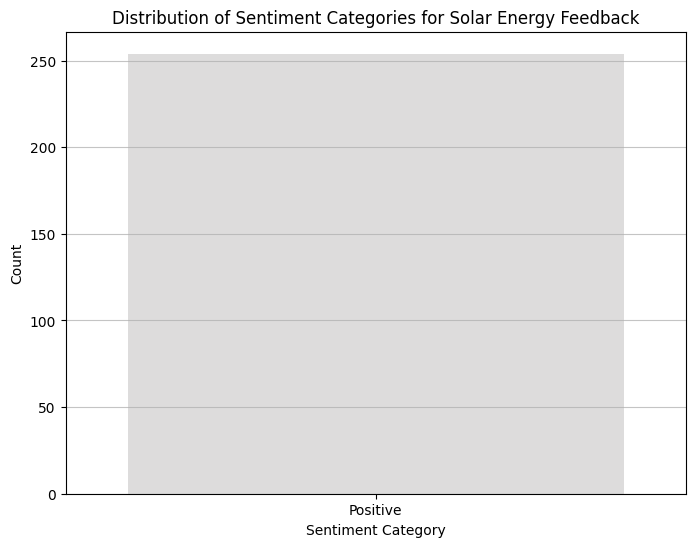

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for solar-specific sentiment
plt.figure(figsize=(8, 6))
sns.barplot(x=solar_sentiment_counts.index, y=solar_sentiment_counts.values, hue=solar_sentiment_counts.index, palette='coolwarm', legend=False)
plt.title('Distribution of Sentiment Categories for Solar Energy Feedback')
plt.xlabel('Sentiment Category')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

This graph specifically visualizes the sentiment for feedback related to 'solar' energy, helping to gauge public preference in this particular area.